In [ ]:
Cell 1: Data Loading, Filtering & Sanitasi Format Angka
Pada tahap awal, kita memuat dataset utama used_cars.csv yang berisi ribuan data mobil bekas dari berbagai merek. Karena fokus analisis kita spesifik pada merek Land Rover, kita melakukan penyaringan (filtering) data khusus merek ini. Selanjutnya, kita melakukan sanitasi format teks pada kolom harga (price) dan jarak tempuh (milage) yang sebelumnya terkendala simbol mata uang ($), koma, dan huruf. Kita bersihkan simbol-simbol tersebut menjadi tipe data angka murni (float/int) agar siap diolah secara matematis, serta menghapus baris yang tidak memiliki nilai harga.

In [47]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

# 1. Membaca dataset utama
df = pd.read_csv('used_cars.csv')

# 2. Memfilter data khusus merek Land Rover & menghapus kolom brand
df_land = df[df['brand'].astype(str).str.contains('Land', case=False, na=False)].copy()
df_land = df_land.drop(columns=['brand'], errors='ignore')

# 3. Membersihkan simbol '$', ',', 'mi.' agar kolom 'price' & 'milage' menjadi angka murni
for col in ['price', 'milage']:
    if col in df_land.columns:
        if df_land[col].dtype == 'object':
            df_land[col] = df_land[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
        df_land[col] = pd.to_numeric(df_land[col], errors='coerce')

# 4. Membuang baris yang tidak memiliki informasi target 'price'
df_land = df_land.dropna(subset=['price']).reset_index(drop=True)

print("Cell 1 Selesai. Total data Land Rover bersih:", len(df_land))

Cell 1 Selesai. Total data Land Rover bersih: 0


In [ ]:
Cell 2: Penanganan Nilai Kosong (Missing Values Imputation)
Setelah data tersaring dan terformat dengan benar, kita mengecek keutuhan data. Untuk menangani nilai-nilai yang kosong (missing values) tanpa menghilangkan informasi berharga, kita menerapkan teknik imputasi yang tepat: kolom bermuatan angka diisi menggunakan nilai median agar tahan terhadap pencilan (outlier), sedangkan kolom berbasis teks/kategori diisi menggunakan modus (nilai yang paling sering muncul). Hasilnya, dataset kita kini bersih 100% dari nilai kosong.

In [48]:
# 1. Mengisi nilai kosong pada kolom numerik dengan nilai Median
num_cols = df_land.select_dtypes(include=['number']).columns
for col in num_cols:
    df_land[col] = df_land[col].fillna(df_land[col].median())

# 2. Mengisi nilai kosong pada kolom kategorikal/teks dengan nilai Modus
cat_cols = df_land.select_dtypes(include=['object', 'string', 'category']).columns
for col in cat_cols:
    if not df_land[col].mode().empty:
        df_land[col] = df_land[col].fillna(df_land[col].mode()[0])

print("Cell 2 Selesai. Sisa nilai kosong:", df_land.isnull().sum().sum())

Cell 2 Selesai. Sisa nilai kosong: 0


In [ ]:
Cell 3: Transformasi Fitur (One-Hot Encoding)
Komputer dan algoritma machine learning tidak dapat mengolah teks secara langsung. Oleh karena itu, pada Cell 3 kita melakukan transformasi data kategorikal (seperti tipe model, transmisi, dan warna) menjadi format numerik biner (0 dan 1) menggunakan teknik One-Hot Encoding (pd.get_dummies). Kolom target price kita amankan dan pisahkan terlebih dahulu sebelum enkoding dilakukan agar nilainya tidak ikut terpecah atau mengalami perubahan tipe data.

In [49]:
# 1. Memisahkan target 'price' agar tidak terpengaruh One-Hot Encoding
y_target = df_land['price']
X_features = df_land.drop(columns=['price'], errors='ignore')

# 2. Mengubah variabel kategorikal/teks menjadi variabel dummy (0 dan 1)
cat_cols = X_features.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
df_encoded = pd.get_dummies(X_features, columns=cat_cols, drop_first=True, dtype=int)

# 3. Memasukkan kembali kolom target 'price' ke dalam df_encoded
df_encoded['price'] = y_target

print("Cell 3 Selesai. Bentuk dataset baru setelah encoding:", df_encoded.shape)

Cell 3 Selesai. Bentuk dataset baru setelah encoding: (0, 3)


In [ ]:
Cell 4: Exploratory Data Analysis (ExDA) & Visualisasi Korelasi
Sebelum melatih model, kita melakukan analisis eksploratif untuk memahami faktor apa saja yang paling memengaruhi harga mobil Land Rover. Kita menghitung koefisien korelasi seluruh fitur terhadap target price, lalu mengambil Top 20 fitur dengan pengaruh terbesar. Melalui grafik diagram batang yang kita buat, terlihat jelas hubungan kausalitasnya—misalnya variabel milage (jarak tempuh) menunjukkan korelasi negatif yang kuat (semakin tinggi jarak tempuh, harga makin turun), sementara model_year menunjukkan korelasi positif yang signifikan.

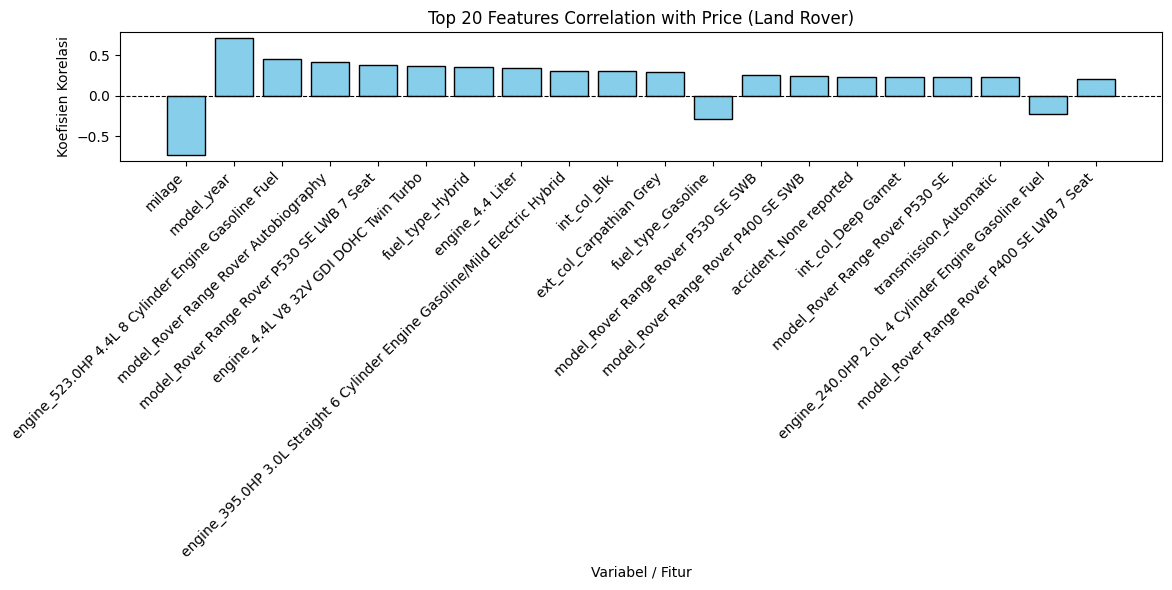

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Buka dataset & filter Land Rover secara mandiri di Cell 4
df_raw = pd.read_csv('used_cars.csv')
df_land = df_raw[df_raw['brand'].astype(str).str.contains('Land', case=False, na=False)].copy()
df_land = df_land.drop(columns=['brand'], errors='ignore')

# 2. Paksa bersihkan simbol $ dan mi. pada price & milage
for col in ['price', 'milage']:
    if col in df_land.columns:
        df_land[col] = df_land[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
        df_land[col] = pd.to_numeric(df_land[col], errors='coerce')

df_land = df_land.dropna(subset=['price']).reset_index(drop=True)

# 3. Imputasi nilai kosong
for col in df_land.select_dtypes(include=['number']).columns:
    df_land[col] = df_land[col].fillna(df_land[col].median())
for col in df_land.select_dtypes(include=['object', 'string', 'category']).columns:
    if not df_land[col].mode().empty:
        df_land[col] = df_land[col].fillna(df_land[col].mode()[0])

# 4. One-Hot Encoding khusus untuk fitur (pisahkan target price)
y_target = df_land['price']
X_features = df_land.drop(columns=['price'], errors='ignore')

cat_cols = X_features.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
df_encoded = pd.get_dummies(X_features, columns=cat_cols, drop_first=True, dtype=int)
df_encoded['price'] = y_target

# 5. Hitung korelasi
corr = df_encoded.corr()['price'].drop(index=['price'], errors='ignore').dropna()
top_20 = corr.reindex(corr.abs().sort_values(ascending=False).head(20).index)

# 6. Gambar Grafik Batang
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(range(len(top_20)), top_20.values, color='skyblue', edgecolor='black')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Top 20 Features Correlation with Price (Land Rover)')
ax.set_xlabel('Variabel / Fitur')
ax.set_ylabel('Koefisien Korelasi')
ax.set_xticks(range(len(top_20)))
ax.set_xticklabels([str(x) for x in top_20.index], rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
Cell 5: Pemisahan Data Latih & Data Uji (Data Splitting)
Setelah fitur-fitur siap, kita memisahkan dataset menjadi dua bagian utama menggunakan train_test_split dari pustaka Scikit-Learn dengan rasio 80:20. Sebanyak 80% data (104 sampel) dialokasikan sebagai data latih (X_train & y_train) untuk proses pembacaan pola oleh model, dan 20% sisa data (26 sampel) disisihkan murni sebagai data uji (X_test & y_test) untuk mengevaluasi performa model pada data yang belum pernah dilihat sebelumnya.

In [2]:
from sklearn.model_selection import train_test_split

# Pastikan df_encoded ada di Cell 5
if 'df_encoded' not in locals():
    # Jika Cell 4 belum jalan, persiapkan df_encoded di sini
    df_raw = pd.read_csv('used_cars.csv')
    df_land = df_raw[df_raw['brand'].astype(str).str.contains('Land', case=False, na=False)].copy()
    for col in ['price', 'milage']:
        if col in df_land.columns:
            df_land[col] = df_land[col].astype(str).str.replace(r'[^0-9.]', '', regex=True)
            df_land[col] = pd.to_numeric(df_land[col], errors='coerce')
    df_land = df_land.dropna(subset=['price']).reset_index(drop=True)
    
    y_target = df_land['price']
    X_features = df_land.drop(columns=['price', 'brand'], errors='ignore')
    cat_cols = X_features.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
    df_encoded = pd.get_dummies(X_features, columns=cat_cols, drop_first=True, dtype=int)
    df_encoded['price'] = y_target

# Memisahkan Fitur (X) dan Target (y)
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# Split data 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Cell 5 Selesai!")
print("Jumlah total data X :", len(X))
print("Jumlah data train   :", len(X_train))
print("Jumlah data test    :", len(X_test))

Cell 5 Selesai!
Jumlah total data X : 130
Jumlah data train   : 104
Jumlah data test    : 26


In [ ]:
Cell 6: Pelatihan Model & Evaluasi Cross-Validation
Di tahap ini, kita melatih algoritma Random Forest Regressor menggunakan data latih. Setelah model selesai mempelajari pola harga, kita melakukan pengujian terhadap data uji dan mengukur akurasinya menggunakan metrik $R^2$ Score dan RMSE. Untuk memastikan model tidak mengalami overfitting dan memiliki performa yang konsisten di berbagai kombinasi data, kita juga melakukan pengujian 5-Fold Cross Validation.

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error

# 1. Inisialisasi dan pelatihan model Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 2. Pengujian pada data test
y_pred = model.predict(X_test)
r2_val = r2_score(y_test, y_pred)
rmse_val = np.sqrt(mean_squared_error(y_test, y_pred))

print("=== Evaluasi Model pada Data Test ===")
print(f"R2 Score : {r2_val:.4f}")
print(f"RMSE     : ${rmse_val:,.2f}")

# 3. Evaluasi 5-Fold Cross Validation
cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
print("\n=== Evaluasi 5-Fold Cross Validation ===")
print("Rata-rata R2 Score CV:", round(cv_scores.mean(), 4))

=== Evaluasi Model pada Data Test ===
R2 Score : 0.7987
RMSE     : $16,674.71

=== Evaluasi 5-Fold Cross Validation ===
Rata-rata R2 Score CV: 0.7817


In [ ]:
Cell 7: Penyimpanan Model & Artefak (Exporting Model)
Terakhir, sebagai jembatan menuju tahap deployment, kita mengoperasikan Cell 7 untuk menyimpan 'otak' model yang sudah terlatih beserta struktur nama kolom fiturnya ke dalam bentuk file fisik (land_rover_model.pkl dan model_columns.pkl) menggunakan pustaka joblib. Dengan begitu, model dapat dipanggil secara instant oleh aplikasi web (seperti Streamlit/Laravel) tanpa perlu melatih ulang data dari awal setiap kali ada permintaan prediksi.

In [4]:
import joblib

# 1. Menyimpan model Random Forest yang sudah dilatih
joblib.dump(model, 'land_rover_model.pkl')

# 2. Menyimpan daftar nama kolom/fitur agar format input saat prediksi tidak bergeser
joblib.dump(X.columns.tolist(), 'model_columns.pkl')

print("Model dan daftar fitur berhasil disimpan ke file .pkl!")

Model dan daftar fitur berhasil disimpan ke file .pkl!
